In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

In [2]:
x,y=make_blobs(n_samples=10000,n_features=2,centers=3)

In [3]:
df=pd.DataFrame(x,columns=['f1','f2'])

In [4]:
df=pd.concat([df,pd.DataFrame(y,columns=['Labels_True'])],axis=1)

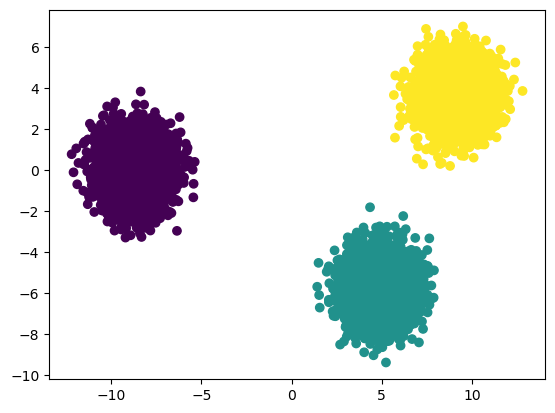

In [5]:
plt.scatter(df['f1'],df['f2'],c=y)

In [6]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [7]:
wcss=[]

In [8]:
for i in range(1,11):
    kmeans=KMeans(n_clusters=i)
    kmeans.fit(x_train)
    wcss.append(kmeans.inertia_)

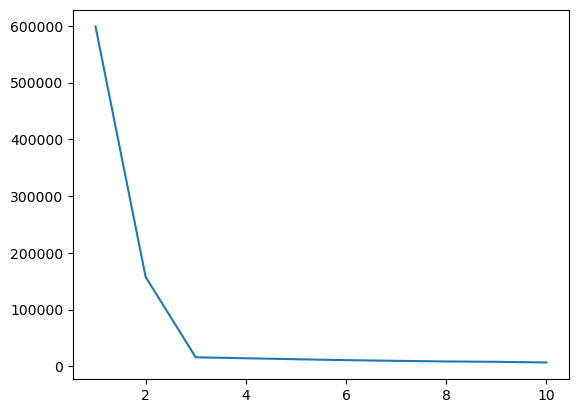

In [9]:
plt.plot(range(1,11),wcss)

In [10]:
kmeans=KMeans(n_clusters=3)

In [11]:
y_labels=kmeans.fit_predict(x_train)

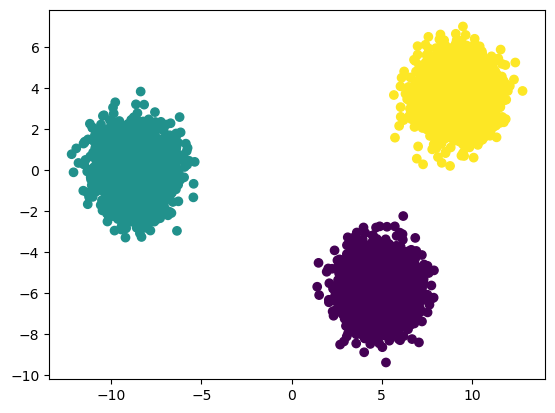

In [12]:
plt.scatter(x_train[:,0],x_train[:,1],c=y_labels)

<Axes: >

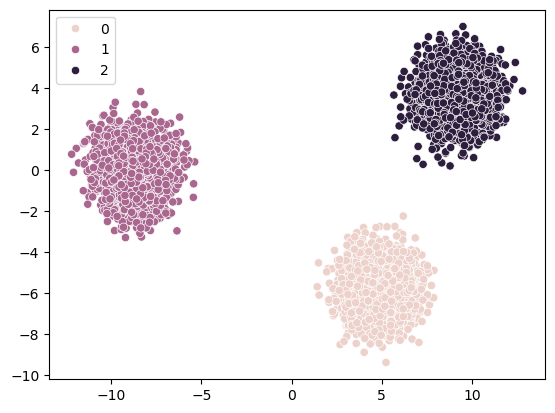

In [13]:
sns.scatterplot(x=x_train[:,0],y=x_train[:,1],hue=y_labels)

In [14]:
pip install kneed

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [15]:
from kneed import KneeLocator

In [16]:
kl=KneeLocator(range(1,11),wcss,curve='convex',direction='decreasing')

In [17]:
kl.elbow

np.int64(3)